# 02 — Clean the queue data

This notebook applies cleaning rules R1–R9 to the LBNL project file, one rule
at a time with a before/after table for each, and saves the clean table every
later notebook starts from.

**Inputs → Outputs**

| | Path | Notes |
|---|---|---|
| in | `data/raw/lbnl/lbnl_ix_queue_data_file_thru2024_v2.xlsx` | frozen release, verified by SHA-256 |
| out | `data/interim/queue_clean.parquet` | clean table, one row per generation request |
| out | `results/clean_log.csv` | rows touched by each rule (pinned by `tests/test_cleaning.py`) |
| out | `results/clean_checks.csv` | the notebook's acceptance checks, PASS/FAIL |
| out | `figures/02_clean_queue_data/*.png|svg`, `report/figure_notes.md` | 9 exploratory figures + caption stubs |

## Setup

The rules live in `src/cleaning.py`, one function each. `cleaning.apply_rule()`
runs a rule and appends what it touched to `log`, which becomes
`results/clean_log.csv`.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import cleaning, config, get_lbnl, paths, plots

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

NOTEBOOK = "02_clean_queue_data"
TRACK_A = config.TRACK_A_REGIONS


def save(fig, name, caption):
    """Save a figure of this notebook under figures/02_clean_queue_data/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)


def pct(x, digits=1):
    """Format a share as a percentage string."""
    return f"{100 * x:.{digits}f}%"


DATE_COLS = config.LBNL_DATE_COLS
STATUSES = ["operational", "withdrawn", "active", "suspended"]

## 1. Load the raw sheet

The frozen workbook is verified again (`get_lbnl.download()` checks the
SHA-256) and read exactly as published.

In [2]:
raw = get_lbnl.load_queue(get_lbnl.download())
log = []
print("Rows in:", f"{len(raw):,}", "| columns:", raw.shape[1])

Rows in: 36,441 | columns: 31


## 2. R1 — convert the dates from Excel serial numbers

**What:** the five date columns become real dates. **Why:** LBNL stores them as
Excel day numbers (43511 = 2019-02-15), which cannot be compared or subtracted
as dates. The table shows each column's type and range before and after.

In [3]:
step1 = cleaning.apply_rule(cleaning.r1_convert_dates, raw, log)
pd.DataFrame({
    "type before": [str(raw[c].dtype) for c in DATE_COLS],
    "example before": [raw[c].dropna().iloc[0] for c in DATE_COLS],
    "type after": [str(step1[c].dtype) for c in DATE_COLS],
    "earliest after": [step1[c].min().date() for c in DATE_COLS],
    "latest after": [step1[c].max().date() for c in DATE_COLS],
    "values": [int(step1[c].notna().sum()) for c in DATE_COLS],
}, index=DATE_COLS)

,type before,example before,type after,earliest after,latest after,values
q_date,float64,43511.0,datetime64[ns],1970-01-01,2024-12-31,35834
prop_date,float64,39539.0,datetime64[ns],1905-06-23,2050-12-31,29029
on_date,float64,41274.0,datetime64[ns],1924-02-28,2024-12-30,2957
wd_date,float64,38860.0,datetime64[ns],1999-06-26,2025-02-19,10138
ia_date,float64,42326.0,datetime64[ns],1970-01-01,2024-12-30,2440


**Reading this.** All five date columns are now real dates, and their ranges already show what R2–R4 have to deal with: request dates start at 1970-01-01 (the placeholder), operation dates go back to 1924-02-28, proposed online dates run from 1905-06-23 to 2050-12-31, and withdrawal dates reach 2025-02-19, after the censor date. 35,834 request dates, 2,957 operation dates and 10,138 withdrawal dates are present.

## 3. R2 — placeholder dates become missing; `q_year` follows `q_date`

**What:** 1970-01-01 in `q_date` and `ia_date` is set to missing and `q_year`
is recomputed from `q_date`. **Why:** 1970-01-01 is the Unix epoch, a fill
value; left in, those projects would look 50 years old.

In [4]:
step2 = cleaning.apply_rule(cleaning.r2_placeholder_dates, step1, log)
placeholder = pd.Timestamp(config.PLACEHOLDER_Q_DATE)
pd.DataFrame({
    "before R2": [int((step1["q_date"] == placeholder).sum()), int((step1["ia_date"] == placeholder).sum()),
                  int((step1["q_year"] == 1970).sum()), int(step1["q_year"].isna().sum())],
    "after R2": [int((step2["q_date"] == placeholder).sum()), int((step2["ia_date"] == placeholder).sum()),
                 int((step2["q_year"] == 1970).sum()), int(step2["q_year"].isna().sum())],
}, index=["q_date = 1970-01-01", "ia_date = 1970-01-01", "q_year = 1970", "q_year missing"])

,before R2,after R2
q_date = 1970-01-01,204,0
ia_date = 1970-01-01,56,0
q_year = 1970,204,0
q_year missing,607,811


In [5]:
moved = step1["q_date"] == placeholder
step1.loc[moved, "region"].value_counts().rename("placeholder q_date rows").to_frame().T

region,West,Southeast,ERCOT,PJM,MISO,ISO-NE,CAISO,SPP,NYISO
placeholder q_date rows,73,46,25,24,14,9,7,5,1


**Reading this.** R2 removes all 204 placeholder request dates and 56 placeholder IA dates. The 204 placeholder rows are exactly the rows whose `q_year` read 1970, so recomputing `q_year` changes those 204 values and nothing else; `q_year` is now missing for 811 rows (the 607 that never had a date plus the 204). The plan's "607 year mismatches" are therefore missing years, not disagreements. The placeholders sit mostly in the West (73), the Southeast (46), ERCOT (25) and PJM (24). Without a request date these rows cannot enter either model, because the clock has no start.

## 4. R3 — operation dates must fit the status and the request date

**What:** `on_date` is cleared when the status is not operational, when it is
earlier than the request date, or when it is before 1950. **Why:** the status
is the more recent field, and a project cannot start operating before it asked
to connect. The row is kept — only the impossible date goes.

In [6]:
step3 = cleaning.apply_rule(cleaning.r3_operation_dates, step2, log)
pd.DataFrame({
    "rows with on_date, before R3": step2.groupby("q_status")["on_date"].count(),
    "after R3": step3.groupby("q_status")["on_date"].count(),
}).reindex(STATUSES + ["unknown"])

,"rows with on_date, before R3",after R3
q_status,,
operational,2361,2292
withdrawn,543,0
active,26,0
suspended,27,0
unknown,0,0


## 5. R4 — withdrawal dates must fit the status and the request date

**What:** `wd_date` is cleared when the status is not withdrawn or when it is
earlier than the request date. **Why:** same reasoning as R3. Withdrawal dates
after the censor date are left for notebook 04, which censors them.

In [7]:
step4 = cleaning.apply_rule(cleaning.r4_withdrawal_dates, step3, log)
pd.DataFrame({
    "rows with wd_date, before R4": step3.groupby("q_status")["wd_date"].count(),
    "after R4": step4.groupby("q_status")["wd_date"].count(),
}).reindex(STATUSES + ["unknown"])

,"rows with wd_date, before R4",after R4
q_status,,
operational,0,0
withdrawn,10115,10111
active,6,0
suspended,17,0
unknown,0,0


The figure puts R3 and R4 side by side: for each status, the share of rows that
carry an operation date and a withdrawal date, before R3 and after R4.

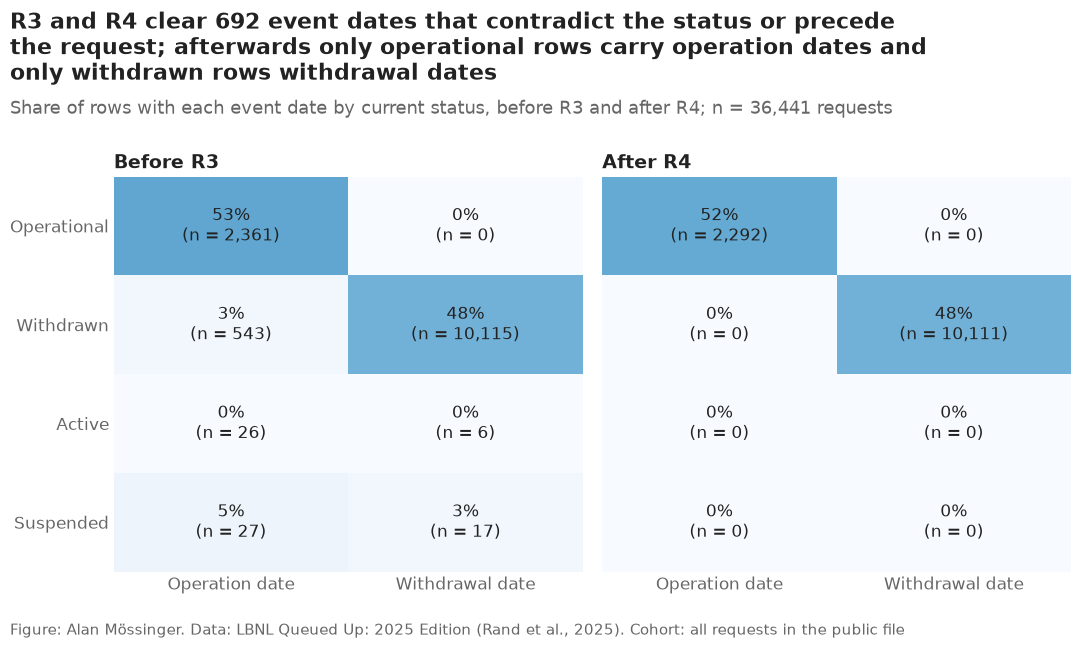

In [8]:
def date_presence(frame):
    """Share of rows with on_date / wd_date by status."""
    return (frame.groupby("q_status")[["on_date", "wd_date"]].agg(lambda s: s.notna().mean())
            .reindex(STATUSES))


panels = {"Before R3": date_presence(step2), "After R4": date_presence(step4)}
counts = {"Before R3": step2.groupby("q_status")[["on_date", "wd_date"]].count().reindex(STATUSES),
          "After R4": step4.groupby("q_status")[["on_date", "wd_date"]].count().reindex(STATUSES)}
fig, axes = plt.subplots(1, 2, sharey=True)
for ax, (title, share) in zip(axes, panels.items()):
    ax.imshow(share.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks([0, 1], ["Operation date", "Withdrawal date"])
    ax.set_yticks(range(len(STATUSES)), [s.capitalize() for s in STATUSES])
    ax.set_title(title)
    ax.grid(False)
    ax.tick_params(length=0)
    for side in ax.spines.values():
        side.set_visible(False)
    for i in range(share.shape[0]):
        for j in range(share.shape[1]):
            value = share.iat[i, j]
            ax.text(j, i, f"{value:.0%}\n(n = {counts[title].iat[i, j]:,})", ha="center", va="center",
                    fontsize=12, color="white" if value > 0.6 else plots.INK)
cleared = int(sum(row["rows"] for row in log if row["rule"] in ("R3", "R4")))
plots.finish(fig,
             f"R3 and R4 clear {cleared:,} event dates that contradict the status or precede the request; "
             "afterwards only operational rows carry operation dates and only withdrawn rows withdrawal dates",
             "Share of rows with each event date by current status, before R3 and after R4; n = "
             f"{len(step4):,} requests",
             "all requests in the public file")
save(fig, "02_01_event_dates_vs_status",
     "Share of rows carrying an operation date and a withdrawal date by status, before and after rules R3–R4.")
plt.show()

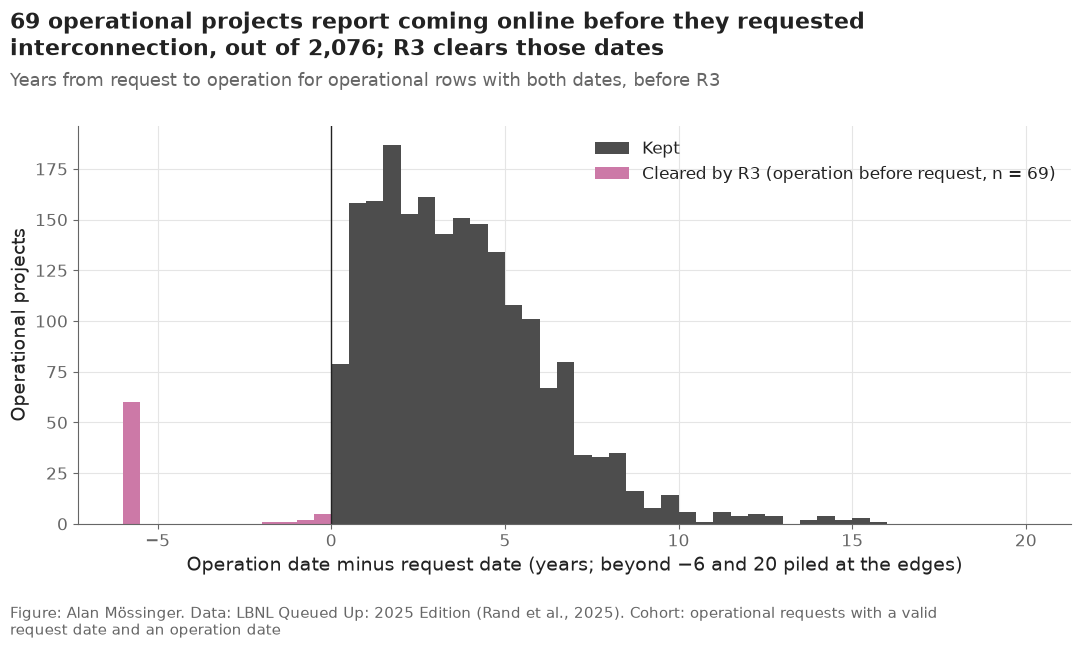

Cleared rows by region: {'West': 52, 'ERCOT': 10, 'PJM': 4, 'CAISO': 2, 'Southeast': 1}


In [9]:
operational = step2[(step2["q_status"] == "operational") & step2["on_date"].notna() & step2["q_date"].notna()]
years = (operational["on_date"] - operational["q_date"]).dt.days / config.DAYS_PER_YEAR
negative = years < 0

fig, ax = plt.subplots()
bins = np.arange(-6, 20.5, 0.5)
ax.hist(years[~negative].clip(upper=20), bins=bins, color="#4D4D4D", label="Kept")
ax.hist(years[negative].clip(lower=-6), bins=bins, color=config.OUTCOME_COLORS["withdrawal"],
        label=f"Cleared by R3 (operation before request, n = {int(negative.sum())})")
ax.axvline(0, color=plots.INK, linewidth=1)
ax.set_xlabel("Operation date minus request date (years; beyond −6 and 20 piled at the edges)")
ax.set_ylabel("Operational projects")
ax.legend(loc="upper right")
plots.finish(fig,
             f"{int(negative.sum())} operational projects report coming online before they requested "
             f"interconnection, out of {len(operational):,}; R3 clears those dates",
             "Years from request to operation for operational rows with both dates, before R3",
             "operational requests with a valid request date and an operation date")
save(fig, "02_02_operation_before_request",
     "Distribution of years from request to operation for operational projects, with the negative values "
     "removed by rule R3 highlighted.")
plt.show()
print("Cleared rows by region:", operational.loc[negative, "region"].value_counts().to_dict())

**Reading this.** R3 clears 596 operation dates on rows that are not operational (543 withdrawn, 26 active, 27 suspended) and 69 that precede their own request date; none is left before 1950. R4 clears 23 withdrawal dates on rows that are not withdrawn (6 active, 17 suspended) and 4 that precede the request. Afterwards the only operation dates are on operational rows and the only withdrawal dates on withdrawn rows (02_01). Of the 69 operation-before-request cases, 52 are in the West and 10 in ERCOT, and the histogram shows most of them are more than six years "early" — too large for a typing slip, but the file does not say what they are. The rows stay in the table; only the date that cannot be right is removed, so an operational project without a valid operation date simply drops out of the timing sample in notebook 04.

## 6. R5 — generation requests only

**What:** rows whose `project_type` is Surplus, Upgrade or Replacement are
dropped; Generation and missing are kept. **Why:** those requests change an
existing plant's interconnection instead of proposing a new plant, so they
follow a different process and would blur the outcome the project models.

In [10]:
step5 = cleaning.apply_rule(cleaning.r5_generation_only, step4, log)
pd.DataFrame({"before R5": step4["project_type"].value_counts(dropna=False),
              "after R5": step5["project_type"].value_counts(dropna=False)}).fillna(0).astype(int)

,before R5,after R5
project_type,,
Generation,33454,33454
Replacement,15,0
Surplus,112,0
Upgrade,81,0
NaN,2779,2779


In [11]:
pd.crosstab(step4.loc[~step4.index.isin(step5.index), "region"],
            step4.loc[~step4.index.isin(step5.index), "project_type"], margins=True)

project_type,Replacement,Surplus,Upgrade,All
region,,,,
MISO,0,41,0,41
PJM,0,0,53,53
SPP,15,66,0,81
Southeast,0,5,28,33
All,15,112,81,208


**Reading this.** R5 drops 208 requests: 112 Surplus, 81 Upgrade and 15 Replacement. They come from SPP (81), PJM (53), MISO (41) and the Southeast (33); none from CAISO or ERCOT. The 2,779 rows with no `project_type` are kept, as planned.

## 7. R6 — total capacity; drop non-positive; flag very large

**What:** `mw = mw1 + mw2 + mw3`; rows with `mw ≤ 0` are dropped; rows above
5,000 MW are flagged in `mw_large` but kept. **Why:** a request cannot have
zero or negative capacity, while a few multi-gigawatt requests are real.

In [12]:
step6 = cleaning.apply_rule(cleaning.r6_capacity, step5, log)
mw_before = step5[["mw1", "mw2", "mw3"]].sum(axis=1, min_count=1)
print("Non-positive mw before R6:", int((mw_before <= 0).sum()), "| after:", int((step6["mw"] <= 0).sum()))
print("Rows with mw <= 0 in the raw file (some already dropped by R5):",
      int((raw[["mw1", "mw2", "mw3"]].sum(axis=1, min_count=1) <= 0).sum()))
step6.loc[step6["mw_large"], ["q_id", "region", "state", "type_clean", "q_status", "q_year",
                               "mw1", "mw2", "mw", "project_name"]]

Non-positive mw before R6: 16 | after: 0
Rows with mw <= 0 in the raw file (some already dropped by R5): 17


,q_id,region,state,type_clean,q_status,q_year,mw1,mw2,mw,project_name
29275,61,Southeast,MS,Other,withdrawn,1999,16875.0,NaN,16875.0,NaN
35532,1402,CAISO,AZ,Solar+Battery,active,2017,3200.0,1920.0,5120.0,ATLAS COMPLEX


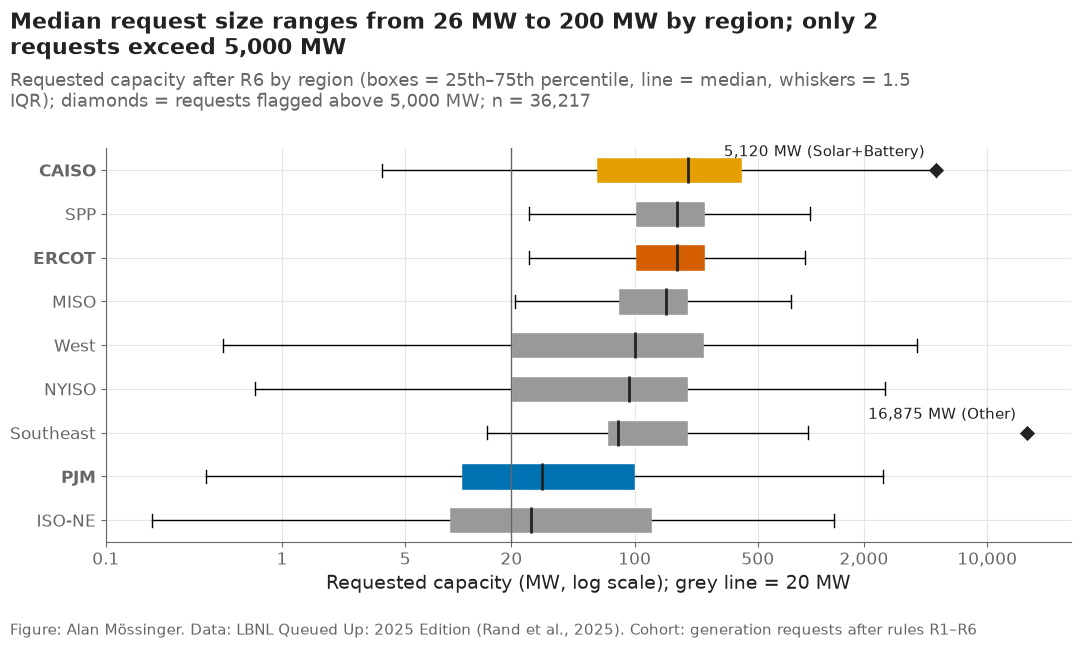

,count,mean,std,min,25%,50%,75%,max
region,,,,,,,,
CAISO,2837.0,320.0,421.5,0.0,60.7,200.0,408.5,5120.0
ERCOT,3277.0,208.1,210.7,0.3,100.0,174.6,250.0,3200.0
ISO-NE,1279.0,117.7,216.9,0.0,8.8,26.0,126.0,1350.0
MISO,4929.0,182.0,196.7,0.5,80.0,150.0,200.0,3576.0
NYISO,1817.0,200.2,325.8,0.5,20.0,92.8,200.0,2620.0
PJM,8099.0,106.7,209.6,0.0,10.4,30.0,100.0,2562.7
SPP,2388.0,197.6,175.8,0.1,100.0,175.0,250.0,4000.0
Southeast,3916.0,205.0,397.7,0.1,70.0,80.0,200.0,16875.0
West,7675.0,185.5,266.9,0.0,20.0,100.0,248.4,4000.0


In [13]:
sized = step6.copy()
fig, ax = plt.subplots()
regions = sized.groupby("region")["mw"].median().sort_values().index
box = ax.boxplot([np.log10(sized.loc[sized["region"] == r, "mw"]) for r in regions],
                 orientation="horizontal", tick_labels=regions, showfliers=False, widths=0.6,
                 patch_artist=True, medianprops={"color": plots.INK, "linewidth": 2})
for patch, region in zip(box["boxes"], regions):
    patch.set_facecolor(plots.region_color(region))
    patch.set_edgecolor("white")
large = sized[sized["mw_large"]]
ax.scatter(np.log10(large["mw"]), [list(regions).index(r) + 1 for r in large["region"]],
           color=plots.INK, marker="D", s=60, zorder=3)
for _, row in large.iterrows():
    ax.annotate(f"{row['mw']:,.0f} MW ({row['type_clean']})",
                (np.log10(row["mw"]), list(regions).index(row["region"]) + 1),
                xytext=(-8, 10), textcoords="offset points", ha="right", fontsize=11)
ax.axvline(np.log10(config.FERC_SIZE_STEP_MW), color=plots.MUTED, linewidth=1)
ticks = [0.1, 1, 5, 20, 100, 500, 2000, 10000]
ax.set_xticks(np.log10(ticks), [f"{t:,}" for t in ticks])
ax.set_xlabel("Requested capacity (MW, log scale); grey line = 20 MW")
for label in ax.get_yticklabels():
    if label.get_text() in TRACK_A:
        label.set_fontweight("bold")
plots.finish(fig,
             f"Median request size ranges from {sized.groupby('region')['mw'].median().min():.0f} MW to "
             f"{sized.groupby('region')['mw'].median().max():.0f} MW by region; only "
             f"{int(sized['mw_large'].sum())} requests exceed 5,000 MW",
             "Requested capacity after R6 by region (boxes = 25th–75th percentile, line = median, whiskers = "
             f"1.5 IQR); diamonds = requests flagged above 5,000 MW; n = {len(sized):,}",
             "generation requests after rules R1–R6")
save(fig, "02_03_capacity_by_region",
     "Distribution of requested capacity (MW, log scale) by region after rule R6, with the two requests "
     "above 5,000 MW marked.")
plt.show()
sized.groupby("region")["mw"].describe().round(1)

**Reading this.** Before R6, 16 rows have a non-positive capacity (the raw file has 17; the 17th was an Upgrade request already removed by R5); after R6 there are none. Two requests exceed 5,000 MW and are flagged, not dropped: a withdrawn 16,875 MW "Other" request in Mississippi from 1999 with no project name — implausible as one plant — and the active 5,120 MW ATLAS COMPLEX solar+battery hybrid in CAISO (3,200 + 1,920 MW), which is plausible. Median request size ranges from 26 MW in ISO-NE and 30 MW in PJM to 200 MW in CAISO; PJM and ISO-NE have many requests below the 20 MW line, so the size regime will matter most there.

## 8. R7 — one key per project

**What:** `project_key = entity | q_id`; where a key repeats, the copy without a
request date is dropped. **Why:** `q_id` alone repeats across transmission
providers, and later notebooks join tables on the key, so it must be unique.

In [14]:
key = step6["entity"].astype(str) + "|" + step6["q_id"].astype(str)
pair = step6[key.duplicated(keep=False)]
step7 = cleaning.apply_rule(cleaning.r7_project_key, step6, log)
print("Key unique after R7:", step7["project_key"].is_unique)
pair[["q_id", "entity", "region", "project_name", "q_status", "q_date", "on_date", "IA_status_clean", "mw"]]

Key unique after R7: True


,q_id,entity,region,project_name,q_status,q_date,on_date,IA_status_clean,mw
12045,505,NYISO,NYISO,Ball Hill Wind,operational,2015-06-02,NaT,Facility Study,103.0
35181,505,NYISO,NYISO,Ball Hill Wind,operational,NaT,2023-10-31,Operational,103.0


**Reading this.** One key repeats: NYISO request 505, "Ball Hill Wind" (103 MW). One copy has the request date (2015-06-02) but no operation date; the other has the operation date (2023-10-31) but no request date. R7 drops the second copy, so the project now counts once; the copy kept is operational but without an operation date. NYISO is not in the timing model, so this matters only for Track B.

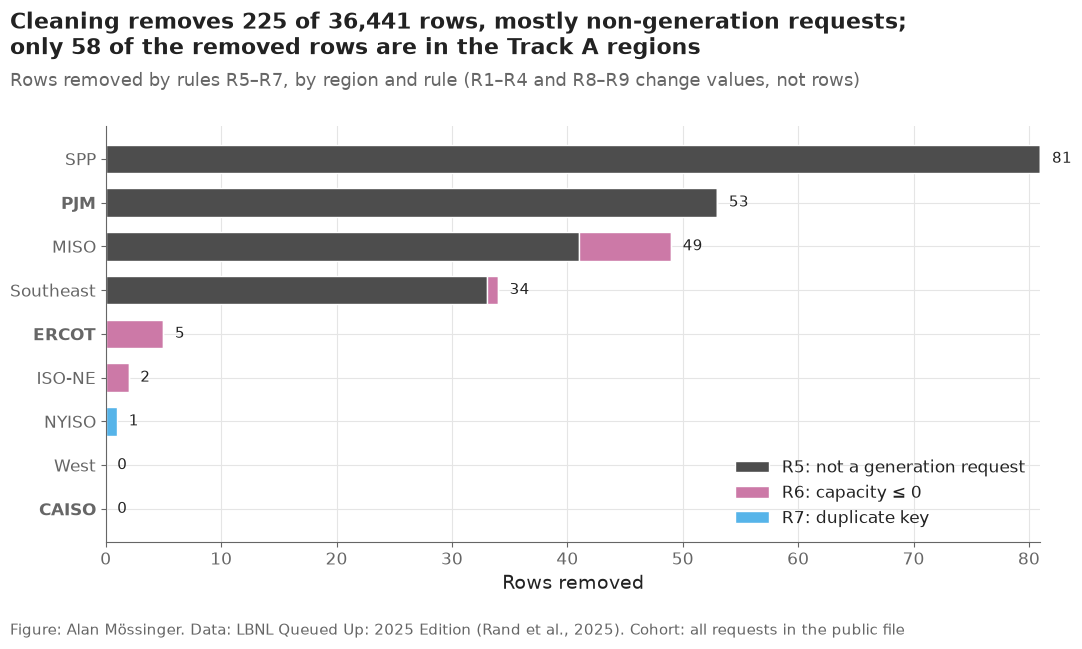

region,CAISO,West,NYISO,ISO-NE,ERCOT,Southeast,MISO,PJM,SPP
R5: not a generation request,0,0,0,0,0,33,41,53,81
R6: capacity ≤ 0,0,0,0,2,5,1,8,0,0
R7: duplicate key,0,0,1,0,0,0,0,0,0


In [15]:
removed = []
for frame_before, frame_after, rule in [(step4, step5, "R5: not a generation request"),
                                        (step5, step6, "R6: capacity ≤ 0"),
                                        (step6, step7, "R7: duplicate key")]:
    gone = frame_before.loc[~frame_before.index.isin(frame_after.index)]
    removed.append(gone["region"].value_counts().rename(rule))
removed = pd.concat(removed, axis=1).reindex(config.ALL_REGIONS).fillna(0).astype(int)
removed = removed.loc[removed.sum(axis=1).sort_values().index]

rule_colors = ["#4D4D4D", config.OUTCOME_COLORS["withdrawal"], "#56B4E9"]
fig, ax = plt.subplots()
left = np.zeros(len(removed))
for column, color in zip(removed.columns, rule_colors):
    ax.barh(removed.index, removed[column], left=left, color=color, height=0.65, label=column,
            edgecolor="white", linewidth=1)
    left += removed[column].values
for i, total in enumerate(removed.sum(axis=1)):
    ax.text(total + 1, i, f"{total}", va="center", fontsize=11)
for label in ax.get_yticklabels():
    if label.get_text() in TRACK_A:
        label.set_fontweight("bold")
ax.set_xlabel("Rows removed")
ax.legend(loc="lower right")
plots.finish(fig,
             f"Cleaning removes {int(removed.values.sum())} of {len(raw):,} rows, mostly non-generation "
             f"requests; only {int(removed.loc[TRACK_A].values.sum())} of the removed rows are in the Track A regions",
             "Rows removed by rules R5–R7, by region and rule (R1–R4 and R8–R9 change values, not rows)",
             "all requests in the public file")
save(fig, "02_04_rows_removed_by_region",
     "Number of rows removed by cleaning rules R5, R6 and R7, by region.")
plt.show()
removed.T

**Reading this.** Cleaning removes 225 rows: 208 by R5, 16 by R6 and 1 by R7. SPP loses the most (81, all non-generation). In the Track A regions only 58 rows go — 53 PJM upgrades and 5 ERCOT rows with non-positive capacity — and CAISO loses none, so the timing sample is barely touched by row removals; its real losses come from missing dates.

## 9. R8 — sparse fields

**What:** `developer` and `cluster` are dropped; missing `service` and `county`
become an explicit "missing" level. **Why:** the first two are blank for most
rows; the last two are useful but often blank, and a "missing" level keeps
those rows in the models.

In [16]:
sparse = step7.groupby("region")[["developer", "cluster", "service", "county"]].agg(
    lambda s: s.notna().mean()).reindex(config.ALL_REGIONS)
step8 = cleaning.apply_rule(cleaning.r8_sparse_fields, step7, log)
print("Columns dropped:", sorted(set(step7.columns) - set(step8.columns)))
(100 * sparse).round(1).rename(columns=lambda c: f"{c} filled (%)")

Columns dropped: ['cluster', 'developer']


,developer filled (%),cluster filled (%),service filled (%),county filled (%)
region,,,,
ERCOT,92.5,0.0,0.8,100.0
PJM,0.0,0.0,99.8,98.5
CAISO,0.0,80.4,75.3,88.9
MISO,0.0,63.8,85.0,65.2
SPP,0.0,65.3,92.8,98.7
NYISO,100.0,20.7,0.0,95.3
ISO-NE,0.0,3.6,69.9,96.2
West,11.9,18.7,88.1,99.4
Southeast,24.7,15.0,74.4,99.1


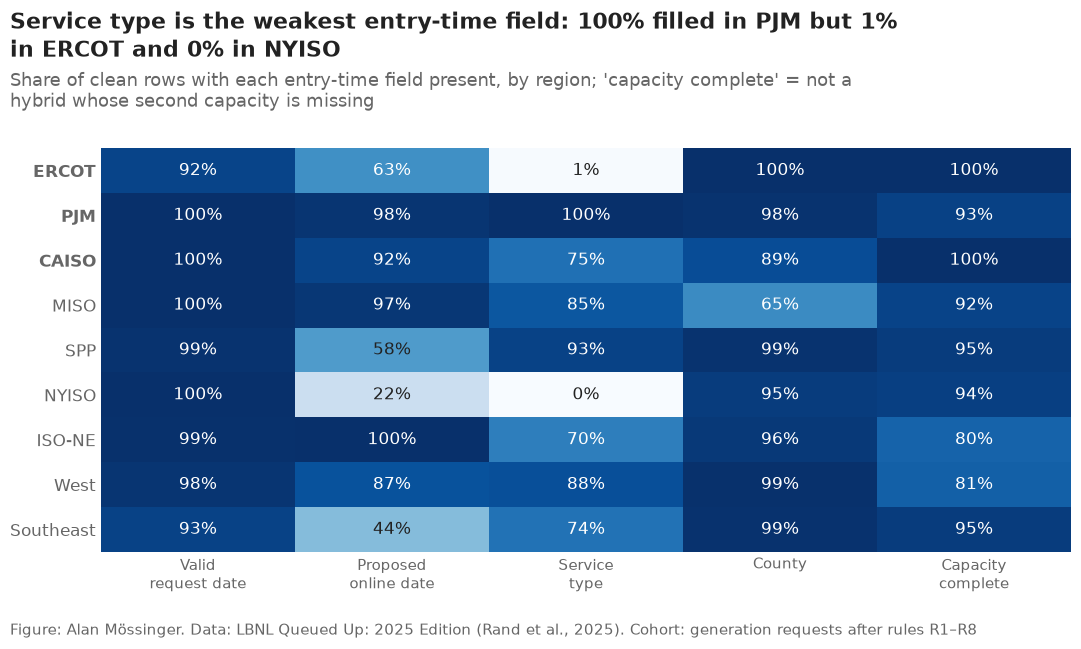

,Valid request date,Proposed online date,Service type,County,Capacity complete
region,,,,,
ERCOT,91.8,63.0,0.8,100.0,100.0
PJM,99.7,98.0,99.8,98.5,93.1
CAISO,99.8,92.0,75.3,88.9,99.9
MISO,99.7,97.2,85.0,65.2,92.2
SPP,98.7,58.4,92.8,98.7,95.1
NYISO,100.0,22.1,0.0,95.3,93.9
ISO-NE,99.3,99.7,69.9,96.2,80.1
West,97.8,87.0,88.1,99.4,81.5
Southeast,92.7,43.5,74.4,99.1,94.9


In [17]:
fields = {"Valid request date": step8["q_date"].notna(),
          "Proposed online date": step8["prop_date"].notna(),
          "Service type": step8["service"] != "missing",
          "County": step8["county"] != "missing",
          "Capacity complete": ~(step8["type2"].notna() & step8["mw2"].isna())}
filled = pd.DataFrame(fields).groupby(step8["region"]).mean().reindex(config.ALL_REGIONS)

fig, ax = plt.subplots()
ax.imshow(filled.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(filled.shape[1]), [c.replace(" ", "\n", 1) for c in filled.columns], fontsize=11)
ax.set_yticks(range(filled.shape[0]), filled.index)
ax.grid(False)
ax.tick_params(length=0)
for side in ax.spines.values():
    side.set_visible(False)
for i in range(filled.shape[0]):
    for j in range(filled.shape[1]):
        value = filled.iat[i, j]
        ax.text(j, i, f"{value:.0%}", ha="center", va="center", fontsize=12,
                color="white" if value > 0.6 else plots.INK)
for label in ax.get_yticklabels():
    if label.get_text() in TRACK_A:
        label.set_fontweight("bold")
worst = filled["Service type"].idxmin()
plots.finish(fig,
             f"Service type is the weakest entry-time field: {filled.loc['PJM', 'Service type']:.0%} filled in "
             f"PJM but {filled.loc['ERCOT', 'Service type']:.0%} in ERCOT and {filled['Service type'].min():.0%} in {worst}",
             "Share of clean rows with each entry-time field present, by region; 'capacity complete' = not a "
             "hybrid whose second capacity is missing",
             "generation requests after rules R1–R8")
save(fig, "02_05_feature_completeness_by_region",
     "Share of clean rows with each entry-time field present, by region.")
plt.show()
(100 * filled).round(1)

**Reading this.** `developer` and `cluster` are dropped (6,724 and 9,424 values). The table shows how uneven they were: `developer` is 92.5% filled in ERCOT and 100% in NYISO but 0% in PJM, CAISO and MISO; `cluster` is 80.4% filled in CAISO and empty in ERCOT and PJM. They could only ever be used inside a single region. 8,998 `service` values and 2,398 `county` values become "missing". Figure 02_05 shows what this means for features: service type is 99.8% filled in PJM but 0.8% in ERCOT and 0.0% in NYISO, so inside ERCOT it carries no information; the proposed online date is thin in NYISO (22.1%) and the Southeast (43.5%), on top of the leakage question from notebook 01.

## 10. R9 — hybrids

**What:** `hybrid = type2 is present`; `type_clean` stays as LBNL standardised
it. **Why:** hybrid composition is a feature, and LBNL warns that hybrid
storage capacity is estimated for some projects (sheet 13, note 2), so the
notebook also counts hybrids with no second capacity at all.

In [18]:
step9 = cleaning.apply_rule(cleaning.r9_hybrid, step8, log)
hyb = step9.groupby("region").agg(requests=("hybrid", "size"), hybrids=("hybrid", "sum"))
hyb["hybrid share"] = hyb["hybrids"] / hyb["requests"]
hyb["hybrids without mw2"] = step9[step9["hybrid"]].groupby("region")["mw2"].apply(lambda s: s.isna().sum())
hyb["share of hybrids without mw2"] = hyb["hybrids without mw2"] / hyb["hybrids"]
hyb = hyb.reindex(config.ALL_REGIONS).fillna(0)
hyb.round(3)

,requests,hybrids,hybrid share,hybrids without mw2,share of hybrids without mw2
region,,,,,
ERCOT,3277,0,0.000,0.0,0.000
PJM,8099,557,0.069,557.0,1.000
CAISO,2837,718,0.253,4.0,0.006
MISO,4929,382,0.078,382.0,1.000
SPP,2388,118,0.049,118.0,1.000
NYISO,1816,110,0.061,110.0,1.000
ISO-NE,1279,254,0.199,254.0,1.000
West,7675,1699,0.221,1421.0,0.836
Southeast,3916,350,0.089,198.0,0.566


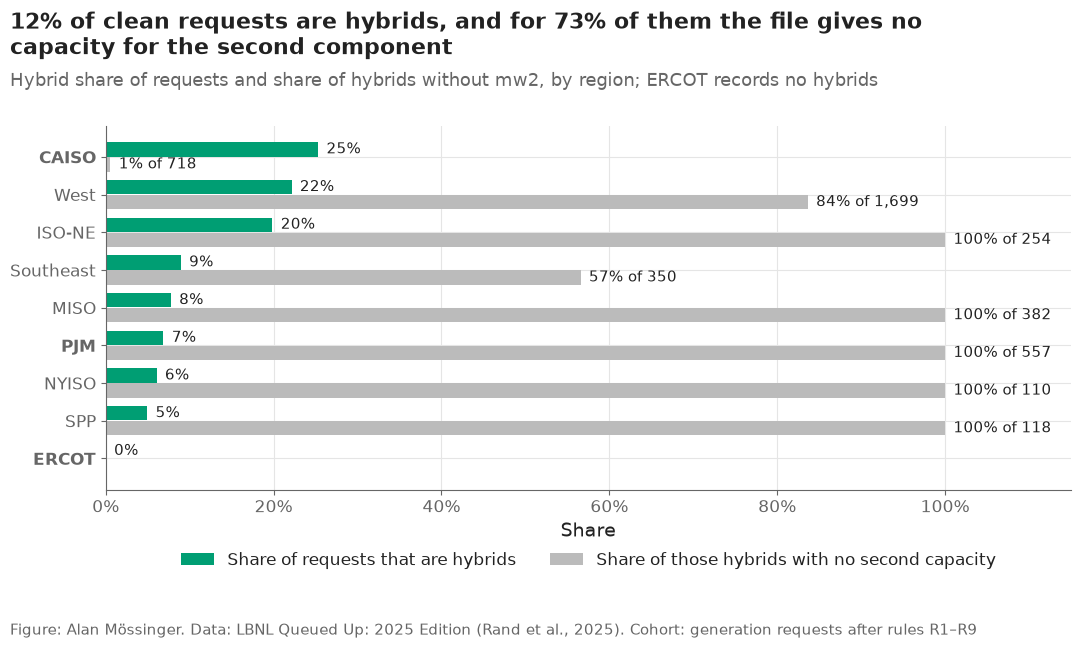

In [19]:
fig, ax = plt.subplots()
order = hyb.sort_values("hybrid share").index
y = np.arange(len(order))
ax.barh(y + 0.2, hyb.loc[order, "hybrid share"], height=0.38, color=config.TECH_COLORS["Solar+Battery"],
        label="Share of requests that are hybrids")
ax.barh(y - 0.2, hyb.loc[order, "share of hybrids without mw2"], height=0.38, color="#BBBBBB",
        label="Share of those hybrids with no second capacity")
for i, region in enumerate(order):
    ax.text(hyb.loc[region, "hybrid share"] + 0.01, i + 0.2, f"{hyb.loc[region, 'hybrid share']:.0%}",
            va="center", fontsize=11)
    if hyb.loc[region, "hybrids"] > 0:
        ax.text(hyb.loc[region, "share of hybrids without mw2"] + 0.01, i - 0.2,
                f"{hyb.loc[region, 'share of hybrids without mw2']:.0%} of {int(hyb.loc[region, 'hybrids']):,}",
                va="center", fontsize=11)
ax.set_yticks(y, order)
for label in ax.get_yticklabels():
    if label.get_text() in TRACK_A:
        label.set_fontweight("bold")
ax.set_xlim(0, 1.15)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_xlabel("Share")
ax.legend(ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.13))
total_share = step9["hybrid"].mean()
no_mw2 = (step9["hybrid"] & step9["mw2"].isna()).sum() / step9["hybrid"].sum()
plots.finish(fig,
             f"{total_share:.0%} of clean requests are hybrids, and for {no_mw2:.0%} of them the file gives "
             "no capacity for the second component",
             "Hybrid share of requests and share of hybrids without mw2, by region; ERCOT records no hybrids",
             "generation requests after rules R1–R9")
save(fig, "02_06_hybrids_by_region",
     "Share of requests that are hybrids, and share of hybrids without a second-component capacity, by region.")
plt.show()

**Reading this.** 4,188 clean requests are hybrids (12%). For 3,044 of them (73%) the file gives no capacity for the second component, so their `mw` is the first component only. The gap is regional: CAISO reports the second capacity for all but 4 of its 718 hybrids, the West lacks it for 84% (1,421 of 1,699), and PJM, MISO, SPP, NYISO and ISO-NE lack it for every hybrid. ERCOT records no hybrids at all. Together with LBNL's note that hybrid storage capacity is estimated for some projects, this makes `mw` a reliable size for single-technology projects but only a lower bound for most hybrids. For notebook 04 I propose using the first component's capacity for size and the hybrid flag for composition, rather than relying on hybrid totals.

## 11. Summary, save, and checks

The clean table is saved with text columns stored as text (some LBNL columns
mix numbers and names, which parquet cannot hold in one column). Then the
acceptance checks of PLAN.md §6 (notebook 02) are run and the rule counts are
compared with the rule table in PLAN.md §7.

In [20]:
clean = step9
clean_log = pd.DataFrame(log)
clean_log.to_csv(paths.RESULTS / "clean_log.csv", index=False)
text_columns = [c for c in clean.columns if clean[c].dtype == object]
clean.astype({c: "string" for c in text_columns}).to_parquet(
    paths.DATA_INTERIM / "queue_clean.parquet", index=False)
print(f"Rows in: {len(raw):,} → rows out: {len(clean):,} ({len(raw) - len(clean)} removed)")
print("Columns:", clean.shape[1])
clean_log[["rule", "item", "rows", "rows_in", "rows_out"]]

Rows in: 36,441 → rows out: 36,216 (225 removed)
Columns: 33


,rule,item,rows,rows_in,rows_out
0,R1,q_date converted,35834,36441,36441
1,R1,prop_date converted,29029,36441,36441
2,R1,on_date converted,2957,36441,36441
3,R1,wd_date converted,10138,36441,36441
4,R1,ia_date converted,2440,36441,36441
5,R2,q_date placeholder set to missing,204,36441,36441
6,R2,ia_date placeholder set to missing,56,36441,36441
7,R2,q_year changed by recomputing it from q_date,204,36441,36441
8,R3,on_date cleared: status is not operational,596,36441,36441
9,R3,on_date cleared: before the request date,69,36441,36441


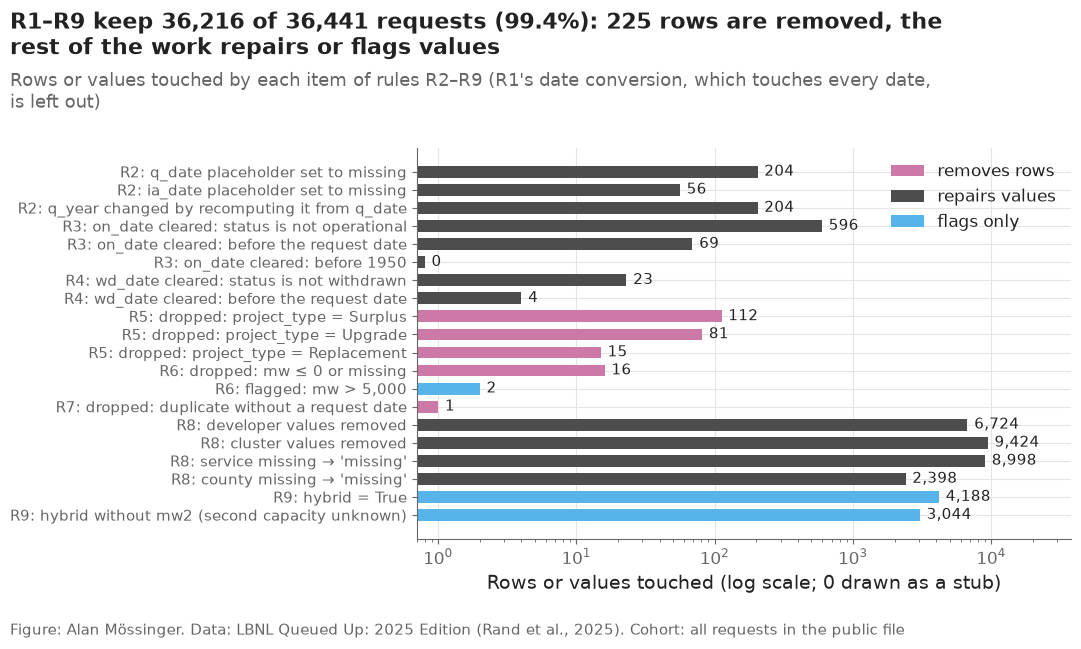

In [21]:
items = clean_log[(clean_log["rule"] != "R1") & (clean_log["item"] != "rows sharing a key")].copy()
items["kind"] = np.select([items["item"].str.startswith("dropped"),
                           items["item"].str.startswith(("flagged", "hybrid"))],
                          ["removes rows", "flags only"], default="repairs values")
items["label"] = items["rule"] + ": " + items["item"]
kind_colors = {"removes rows": config.OUTCOME_COLORS["withdrawal"], "repairs values": "#4D4D4D",
               "flags only": "#56B4E9"}

fig, ax = plt.subplots()
y = np.arange(len(items))[::-1]
ax.barh(y, items["rows"].clip(lower=0.8), color=items["kind"].map(kind_colors), height=0.65)
for yi, value in zip(y, items["rows"]):
    ax.text(max(value, 0.8) * 1.12, yi, f"{value:,}", va="center", fontsize=10.5)
ax.set_yticks(y, items["label"], fontsize=10.5)
ax.set_xscale("log")
ax.set_xlim(0.7, items["rows"].max() * 4)
ax.set_xlabel("Rows or values touched (log scale; 0 drawn as a stub)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c, label=k) for k, c in kind_colors.items()],
          loc="upper right")
plots.finish(fig,
             f"R1–R9 keep {len(clean):,} of {len(raw):,} requests ({len(clean) / len(raw):.1%}): "
             f"{len(raw) - len(clean)} rows are removed, the rest of the work repairs or flags values",
             "Rows or values touched by each item of rules R2–R9 (R1's date conversion, which touches every "
             "date, is left out)",
             "all requests in the public file")
save(fig, "02_07_rules_summary",
     "Number of rows or values touched by each item of cleaning rules R2–R9, by kind of action.")
plt.show()

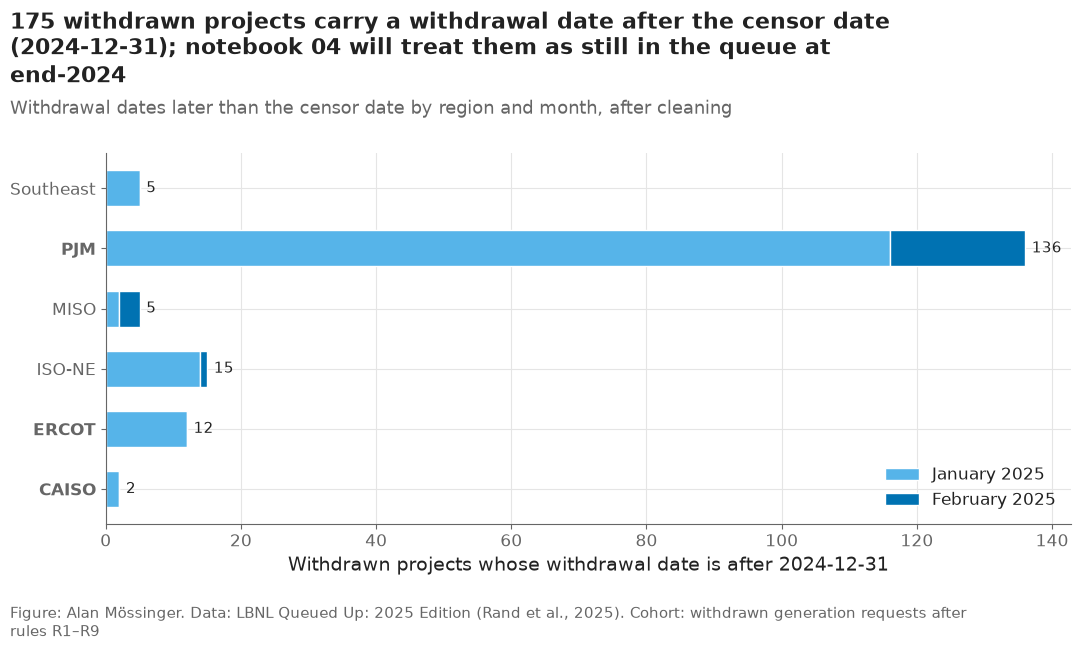

wd_date,2025-01,2025-02
region,,
CAISO,2,0
ERCOT,12,0
ISO-NE,14,1
MISO,2,3
PJM,116,20
Southeast,5,0


In [22]:
censor = pd.Timestamp(config.CENSOR_DATE)
late = clean[clean["wd_date"] > censor]
late_by = late.groupby([late["region"], late["wd_date"].dt.to_period("M")]).size().unstack(fill_value=0)

fig, ax = plt.subplots()
left = np.zeros(len(late_by))
month_colors = ["#56B4E9", "#0072B2", "#4D4D4D"]
for column, color in zip(late_by.columns, month_colors):
    ax.barh(late_by.index, late_by[column], left=left, color=color, height=0.6,
            label=column.strftime("%B %Y"), edgecolor="white", linewidth=1)
    left += late_by[column].values
for i, total in enumerate(late_by.sum(axis=1)):
    ax.text(total + 1, i, f"{total}", va="center", fontsize=11)
for label in ax.get_yticklabels():
    if label.get_text() in TRACK_A:
        label.set_fontweight("bold")
ax.set_xlabel("Withdrawn projects whose withdrawal date is after 2024-12-31")
ax.legend(loc="lower right")
plots.finish(fig,
             f"{len(late)} withdrawn projects carry a withdrawal date after the censor date (2024-12-31); "
             "notebook 04 will treat them as still in the queue at end-2024",
             "Withdrawal dates later than the censor date by region and month, after cleaning",
             "withdrawn generation requests after rules R1–R9")
save(fig, "02_08_withdrawals_after_censor_date",
     "Withdrawn projects whose withdrawal date falls after the 2024-12-31 censor date, by region and month.")
plt.show()
late_by

**Reading this.** 175 withdrawn projects (136 of them in PJM) have a withdrawal date in January or February 2025, after the censor date, although the file describes the queues at the end of 2024. On 2024-12-31 these projects were still in the queue, so notebook 04 will censor them at that date instead of counting a withdrawal; otherwise PJM's withdrawal hazard just before the censor date would be overstated.

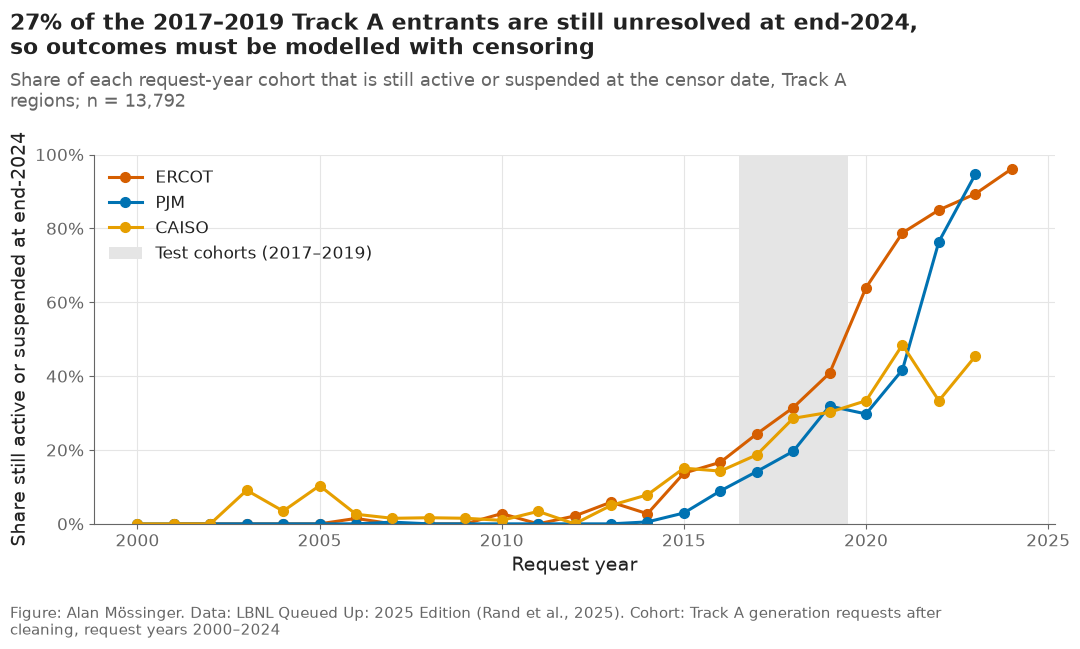

q_year,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
region,,,,,,,,,,,,,,,
CAISO,0.9,3.4,0.0,5.0,7.9,15.1,14.3,18.7,28.6,30.2,33.3,48.5,33.3,45.4,NaN
ERCOT,2.8,0.0,2.1,5.9,2.7,13.7,16.7,24.3,31.5,40.8,64.0,78.8,85.0,89.3,96.1
PJM,0.0,0.0,0.0,0.0,0.5,2.9,8.9,14.2,19.6,31.9,29.8,41.7,76.4,94.6,NaN


In [23]:
track_a = clean[clean["region"].isin(TRACK_A) & clean["q_year"].between(2000, 2024)]
open_share = (track_a.assign(open=track_a["q_status"].isin(["active", "suspended", "unknown"]))
              .groupby(["q_year", "region"])["open"].mean().unstack())

fig, ax = plt.subplots()
for region in TRACK_A:
    ax.plot(open_share.index, open_share[region], color=plots.region_color(region), marker="o", label=region)
ax.axvspan(config.TEST_YEARS[0] - 0.5, config.TEST_YEARS[1] + 0.5, color="#E5E5E5", zorder=0,
           label="Test cohorts (2017–2019)")
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.set_xlabel("Request year")
ax.set_ylabel("Share still active or suspended at end-2024")
ax.legend(loc="upper left")
test_open = track_a[track_a["q_year"].between(*config.TEST_YEARS)]
test_open_share = test_open["q_status"].isin(["active", "suspended", "unknown"]).mean()
plots.finish(fig,
             f"{test_open_share:.0%} of the 2017–2019 Track A entrants are still unresolved at end-2024, "
             "so outcomes must be modelled with censoring",
             "Share of each request-year cohort that is still active or suspended at the censor date, Track A "
             f"regions; n = {len(track_a):,}",
             "Track A generation requests after cleaning, request years 2000–2024")
save(fig, "02_09_unresolved_share_by_cohort",
     "Share of each request-year cohort still active or suspended at the end of 2024, for CAISO, ERCOT and PJM.")
plt.show()
(100 * open_share.loc[2010:]).round(1).T

**Reading this.** The share still unresolved rises steeply with the request year. Within the 2017–2019 test cohorts it is 18.7–30.2% in CAISO, 24.3–40.8% in ERCOT and 14.2–31.9% in PJM; 27% overall. Counting these projects as failures would bias completion downwards, and dropping them would bias it towards fast projects. This is the practical case for time-to-event methods with censoring (notebooks 03–06), and the reason the 7-year horizon can only be evaluated on the 2017 cohort.

The rule table in PLAN.md §7 states six counts, all measured on the raw file.
They are compared on the same rows: for R6 that means checking that all raw
rows with `mw ≤ 0` are gone (one of them is an Upgrade request, so R5 removes
it before R6 sees it). The ">5,000 MW" count is a flag, not a removal; it is
reported but not part of the pass condition, because the plan's "one row" is
simply a miscount that this notebook corrects.

In [24]:
observed = dict(zip(clean_log["item"], clean_log["rows"]))
raw_mw = raw[["mw1", "mw2", "mw3"]].sum(axis=1, min_count=1)
nonpositive_removed = int((~raw.index[raw_mw <= 0].isin(clean.index)).sum())
plan_table = pd.DataFrame([
    ("R2", "request dates that are the 1970-01-01 placeholder", 204,
     observed["q_date placeholder set to missing"], True, ""),
    ("R3", "operation dates on non-operational rows", 596,
     observed["on_date cleared: status is not operational"], True, ""),
    ("R3", "operation dates before the request date", 69,
     observed["on_date cleared: before the request date"], True, ""),
    ("R5–R6", "raw rows with mw ≤ 0 that are removed", 17, nonpositive_removed, True,
     f"{observed['dropped: mw ≤ 0 or missing']} by R6; the other is an Upgrade row removed by R5"),
    ("R7", "duplicate key pairs resolved", 1, observed["dropped: duplicate without a request date"], True, ""),
    ("R6", "requests flagged above 5,000 MW", 1, observed["flagged: mw > 5,000"], False,
     "flag only; the plan names the 16,875 MW row, but a 5,120 MW CAISO hybrid also exceeds 5,000"),
], columns=["rule", "item", "plan", "observed", "in pass condition", "note"])
plan_table["equal"] = plan_table["plan"] == plan_table["observed"]

checks = pd.DataFrame([
    ("no serial-number dates", all(pd.api.types.is_datetime64_any_dtype(clean[c]) for c in DATE_COLS)),
    ("no on_date on non-operational rows", bool(clean.loc[clean["q_status"] != "operational", "on_date"].isna().all())),
    ("no wd_date on non-withdrawn rows", bool(clean.loc[clean["q_status"] != "withdrawn", "wd_date"].isna().all())),
    ("no event date before its request date", not bool(((clean["on_date"] < clean["q_date"]) |
                                                        (clean["wd_date"] < clean["q_date"])).any())),
    ("no non-positive MW", bool((clean["mw"] > 0).all())),
    ("project_key unique", bool(clean["project_key"].is_unique)),
    ("row counts equal the plan's rule table",
     bool(plan_table.loc[plan_table["in pass condition"], "equal"].all())),
], columns=["check", "passed"])
checks["result"] = np.where(checks["passed"], "PASS", "FAIL")
checks.to_csv(paths.RESULTS / "clean_checks.csv", index=False)
print(checks[["check", "result"]].to_string(index=False))
plan_table

                                 check result
                no serial-number dates   PASS
    no on_date on non-operational rows   PASS
      no wd_date on non-withdrawn rows   PASS
 no event date before its request date   PASS
                    no non-positive MW   PASS
                    project_key unique   PASS
row counts equal the plan's rule table   PASS


,rule,item,plan,observed,in pass condition,note,equal
0,R2,request dates that are the 1970-01-01 placeholder,204,204,True,,True
1,R3,operation dates on non-operational rows,596,596,True,,True
2,R3,operation dates before the request date,69,69,True,,True
3,R5–R6,raw rows with mw ≤ 0 that are removed,17,17,True,16 by R6; the other is an Upgrade row removed ...,True
4,R7,duplicate key pairs resolved,1,1,True,,True
5,R6,"requests flagged above 5,000 MW",1,2,False,"flag only; the plan names the 16,875 MW row, b...",False


**Reading this.** All seven checks pass: dates are real dates, event dates agree with the status and never precede the request, every capacity is positive and the project key is unique. Of the six counts in the plan's rule table, the five that clear or remove something are reproduced exactly (204, 596, 69, 17 and 1). The sixth was a miscount in the plan: two requests exceed 5,000 MW, not one, and both are flagged rather than removed. `tests/test_cleaning.py` pins all of these counts.

## Takeaways

- R1–R9 keep 36,216 of 36,441 requests. 225 rows are removed (208 non-generation requests, 16 with non-positive capacity, 1 duplicate), and 692 event dates that contradicted the status or the request date are cleared.
- The plan's rule-table counts reproduce exactly (204, 596, 69, 17, 1); its "one request above 5,000 MW" is in fact two, both flagged and kept.
- Feature caveats for notebook 04: service type is empty in ERCOT and NYISO; 73% of hybrids have no second-component capacity (every hybrid in PJM, MISO, SPP, NYISO and ISO-NE); ERCOT records no hybrids.
- 175 withdrawal dates fall after the censor date (136 in PJM) and will be censored in notebook 04; 27% of the 2017–2019 Track A entrants are still unresolved, so censoring is central to every model.

**What goes to the report:** one paragraph on cleaning in the data section (rows in and out, the date conflicts R3–R4 resolve), 02_09 as the one-figure case for censoring if space allows, and the hybrid-capacity gap in the limitations.